In [280]:
import pandas as pd


**successful_bookings**


In [281]:
df_bookings = pd.read_csv('datasets/fact_bookings.csv')
df_bookings.head()

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
0,May012216558RT11,16558,27-04-22,1/5/2022,2/5/2022,-3.0,RT1,direct online,1.0,Checked Out,10010,10010
1,May012216558RT12,16558,30-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640
2,May012216558RT13,16558,28-04-22,1/5/2022,4/5/2022,2.0,RT1,logtrip,5.0,Checked Out,9100000,9100
3,May012216558RT14,16558,28-04-22,1/5/2022,2/5/2022,-2.0,RT1,others,NaN,Cancelled,9100,3640
4,May012216558RT15,16558,27-04-22,1/5/2022,2/5/2022,4.0,RT1,direct online,5.0,Checked Out,10920,10920


In [282]:
df_bookings.shape

(134590, 12)

In [283]:
df_bookings.room_category.unique()

array(['RT1', 'RT2', 'RT3', 'RT4'], dtype=object)

In [284]:
df_bookings.booking_platform.unique()

array(['direct online', 'others', 'logtrip', 'tripster', 'makeyourtrip',
       'journey', 'direct offline'], dtype=object)

In [285]:
df_bookings.booking_platform.value_counts()

,count
booking_platform,
others,55066
makeyourtrip,26898
logtrip,14756
direct online,13379
tripster,9630
journey,8106
direct offline,6755


<Axes: ylabel='booking_platform'>

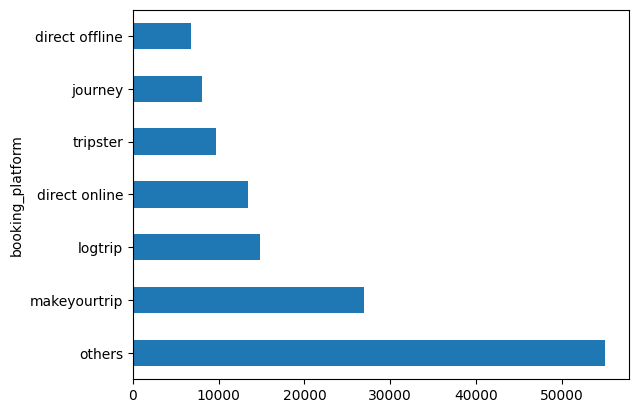

In [286]:
df_bookings.booking_platform.value_counts().plot(kind='barh')

In [287]:
df_bookings.describe()

,property_id,no_guests,ratings_given,revenue_generated,revenue_realized
count,134590.000000,134587.000000,56683.000000,1.345900e+05,134590.000000
mean,18061.113493,2.036170,3.619004,1.537805e+04,12696.123256
std,1093.055847,1.034885,1.235009,9.303604e+04,6928.108124
min,16558.000000,-17.000000,1.000000,6.500000e+03,2600.000000
25%,17558.000000,1.000000,3.000000,9.900000e+03,7600.000000
50%,17564.000000,2.000000,4.000000,1.350000e+04,11700.000000
75%,18563.000000,2.000000,5.000000,1.800000e+04,15300.000000
max,19563.000000,6.000000,5.000000,2.856000e+07,45220.000000


**read all csv files**

In [288]:
df_date = pd.read_csv('datasets/dim_date.csv')
df_hotels = pd.read_csv('datasets/dim_hotels.csv')
df_rooms = pd.read_csv('datasets/dim_rooms.csv')
df_agg_bookings = pd.read_csv('datasets/fact_aggregated_bookings.csv')

In [289]:
df_hotels.head()

,property_id,property_name,category,city
0,16558,Atliq Grands,Luxury,Delhi
1,16559,Atliq Exotica,Luxury,Mumbai
2,16560,Atliq City,Business,Delhi
3,16561,Atliq Blu,Luxury,Delhi
4,16562,Atliq Bay,Luxury,Delhi


In [290]:
df_hotels.shape

(25, 4)

In [291]:
df_hotels.category.value_counts()

,count
category,
Luxury,16
Business,9


<Axes: xlabel='city'>

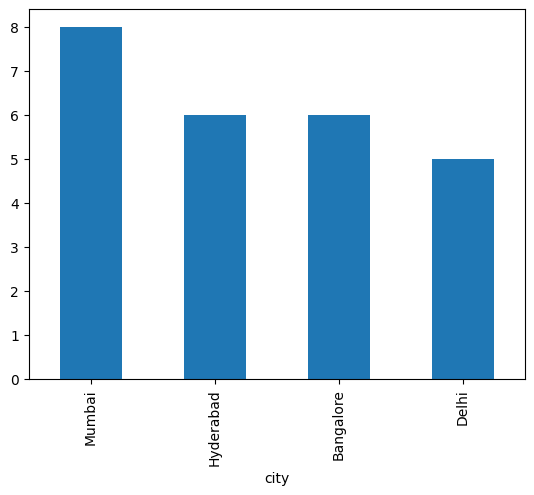

In [292]:
df_hotels.city.value_counts().plot(kind='bar')

**Explore aggregate bookings**

In [293]:
df_agg_bookings.head(3)

,property_id,check_in_date,room_category,successful_bookings,capacity
0,16559,1-May-22,RT1,25,30.0
1,19562,1-May-22,RT1,28,30.0
2,19563,1-May-22,RT1,23,30.0


**unique property id**

In [294]:
df_agg_bookings.property_id.unique()

array([16559, 19562, 19563, 17558, 16558, 17560, 19558, 19560, 17561,
       16560, 16561, 16562, 16563, 17559, 17562, 17563, 18558, 18559,
       18561, 18562, 18563, 19559, 19561, 17564, 18560])

**total booking per id**

In [295]:
df_agg_bookings.groupby('property_id')['successful_bookings'].sum()

,successful_bookings
property_id,
16558,3153
16559,7338
16560,4693
16561,4418
16562,4820
16563,7211
17558,5053
17559,6142
17560,6013


**find out days on which booking are greater than capacity**

In [296]:
df_agg_bookings[df_agg_bookings.successful_bookings > df_agg_bookings.capacity]

,property_id,check_in_date,room_category,successful_bookings,capacity
3,17558,1-May-22,RT1,30,19.0
12,16563,1-May-22,RT1,100,41.0
4136,19558,11-Jun-22,RT2,50,39.0
6209,19560,2-Jul-22,RT1,123,26.0
8522,19559,25-Jul-22,RT1,35,24.0
9194,18563,31-Jul-22,RT4,20,18.0


**find out whose property has highest capacity**

In [297]:
df_agg_bookings.capacity.max()

50.0

In [298]:
df_agg_bookings[df_agg_bookings.capacity == df_agg_bookings.capacity.max()]

,property_id,check_in_date,room_category,successful_bookings,capacity
27,17558,1-May-22,RT2,38,50.0
128,17558,2-May-22,RT2,27,50.0
229,17558,3-May-22,RT2,26,50.0
328,17558,4-May-22,RT2,27,50.0
428,17558,5-May-22,RT2,29,50.0
...,...,...,...,...,...
8728,17558,27-Jul-22,RT2,22,50.0
8828,17558,28-Jul-22,RT2,21,50.0
8928,17558,29-Jul-22,RT2,23,50.0
9028,17558,30-Jul-22,RT2,32,50.0


**data cleaning**

In [299]:
df_bookings.describe()

,property_id,no_guests,ratings_given,revenue_generated,revenue_realized
count,134590.000000,134587.000000,56683.000000,1.345900e+05,134590.000000
mean,18061.113493,2.036170,3.619004,1.537805e+04,12696.123256
std,1093.055847,1.034885,1.235009,9.303604e+04,6928.108124
min,16558.000000,-17.000000,1.000000,6.500000e+03,2600.000000
25%,17558.000000,1.000000,3.000000,9.900000e+03,7600.000000
50%,17564.000000,2.000000,4.000000,1.350000e+04,11700.000000
75%,18563.000000,2.000000,5.000000,1.800000e+04,15300.000000
max,19563.000000,6.000000,5.000000,2.856000e+07,45220.000000


**clean the invalid guest**

In [300]:
df_bookings[df_bookings.no_guests	<= 0]

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
0,May012216558RT11,16558,27-04-22,1/5/2022,2/5/2022,-3.0,RT1,direct online,1.0,Checked Out,10010,10010
3,May012216558RT14,16558,28-04-22,1/5/2022,2/5/2022,-2.0,RT1,others,NaN,Cancelled,9100,3640
17924,May122218559RT44,18559,12/5/2022,12/5/2022,14-05-22,-10.0,RT4,direct online,NaN,No Show,20900,20900
18020,May122218561RT22,18561,8/5/2022,12/5/2022,14-05-22,-12.0,RT2,makeyourtrip,NaN,Cancelled,9000,3600
18119,May122218562RT311,18562,5/5/2022,12/5/2022,17-05-22,-6.0,RT3,direct offline,5.0,Checked Out,16800,16800
18121,May122218562RT313,18562,10/5/2022,12/5/2022,17-05-22,-4.0,RT3,direct online,NaN,Cancelled,14400,5760
56715,Jun082218562RT12,18562,5/6/2022,8/6/2022,13-06-22,-17.0,RT1,others,NaN,Checked Out,6500,6500
119765,Jul202219560RT220,19560,19-07-22,20-07-22,22-07-22,-1.0,RT2,others,NaN,Checked Out,13500,13500
134586,Jul312217564RT47,17564,30-07-22,31-07-22,1/8/2022,-4.0,RT4,logtrip,2.0,Checked Out,38760,38760


In [301]:
df_bookings = df_bookings[df_bookings.no_guests > 0]

In [302]:
df_bookings.shape

(134578, 12)

**outlier removal in revenue generated**

In [303]:
df_bookings.revenue_generated.min(), df_bookings.revenue_generated.max()

(6500, 28560000)

In [304]:
df_bookings.revenue_generated.mean(),df_bookings.revenue_generated.median()

(15378.036937686695, 13500.0)

In [305]:
avg, std = df_bookings.revenue_generated.mean(),df_bookings.revenue_generated.std()

In [306]:
higher_limit = avg + 3*std
higher_limit

294498.50173207896

In [307]:
lower_limit = avg - 3*std
lower_limit

-263742.4278567056

In [308]:
df_bookings[df_bookings.revenue_generated > higher_limit]

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
2,May012216558RT13,16558,28-04-22,1/5/2022,4/5/2022,2.0,RT1,logtrip,5.0,Checked Out,9100000,9100
111,May012216559RT32,16559,29-04-22,1/5/2022,2/5/2022,6.0,RT3,direct online,NaN,Checked Out,28560000,28560
315,May012216562RT22,16562,28-04-22,1/5/2022,4/5/2022,2.0,RT2,direct offline,3.0,Checked Out,12600000,12600
562,May012217559RT118,17559,26-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,2000000,4420
129176,Jul282216562RT26,16562,21-07-22,28-07-22,29-07-22,2.0,RT2,direct online,3.0,Checked Out,10000000,12600


In [309]:
df_bookings = df_bookings[df_bookings.revenue_generated <= higher_limit]
df_bookings.shape

(134573, 12)

In [310]:
df_bookings.revenue_realized.describe()

,revenue_realized
count,134573.000000
mean,12695.983585
std,6927.791692
min,2600.000000
25%,7600.000000
50%,11700.000000
75%,15300.000000
max,45220.000000


In [311]:
higher_limit = df_bookings.revenue_realized.mean() + 3*df_bookings.revenue_realized.std()
higher_limit

33479.358661845814

In [312]:
df_bookings[df_bookings.revenue_realized > higher_limit]

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
137,May012216559RT41,16559,27-04-22,1/5/2022,7/5/2022,4.0,RT4,others,NaN,Checked Out,38760,38760
139,May012216559RT43,16559,1/5/2022,1/5/2022,2/5/2022,6.0,RT4,tripster,3.0,Checked Out,45220,45220
143,May012216559RT47,16559,28-04-22,1/5/2022,3/5/2022,3.0,RT4,others,5.0,Checked Out,35530,35530
149,May012216559RT413,16559,24-04-22,1/5/2022,7/5/2022,5.0,RT4,logtrip,NaN,Checked Out,41990,41990
222,May012216560RT45,16560,30-04-22,1/5/2022,3/5/2022,5.0,RT4,others,3.0,Checked Out,34580,34580
...,...,...,...,...,...,...,...,...,...,...,...,...
134328,Jul312219560RT49,19560,31-07-22,31-07-22,2/8/2022,6.0,RT4,direct online,5.0,Checked Out,39900,39900
134331,Jul312219560RT412,19560,31-07-22,31-07-22,1/8/2022,6.0,RT4,others,2.0,Checked Out,39900,39900
134467,Jul312219562RT45,19562,28-07-22,31-07-22,1/8/2022,6.0,RT4,makeyourtrip,4.0,Checked Out,39900,39900
134474,Jul312219562RT412,19562,25-07-22,31-07-22,6/8/2022,5.0,RT4,direct offline,5.0,Checked Out,37050,37050


In [313]:
df_bookings.room_category.unique()

array(['RT1', 'RT2', 'RT3', 'RT4'], dtype=object)

In [314]:
df_bookings[df_bookings.room_category=='RT4'].revenue_realized.describe()

,revenue_realized
count,16071.000000
mean,23439.308444
std,9048.599076
min,7600.000000
25%,19000.000000
50%,26600.000000
75%,32300.000000
max,45220.000000


In [315]:
# mean + 3 *std
23439 + 3 *9048

50583

In [316]:
df_bookings.isnull().sum()

,0
booking_id,0
property_id,0
booking_date,0
check_in_date,0
checkout_date,0
no_guests,0
room_category,0
booking_platform,0
ratings_given,77897
booking_status,0


In [317]:
df_agg_bookings.isnull().sum()

,0
property_id,0
check_in_date,0
room_category,0
successful_bookings,0
capacity,2


In [318]:
df_agg_bookings.capacity.median()

25.0

In [319]:
df_agg_bookings.capacity.fillna(df_agg_bookings.capacity.median(),inplace=True)

In [320]:
df_agg_bookings.loc[[8,15]]

,property_id,check_in_date,room_category,successful_bookings,capacity
8,17561,1-May-22,RT1,22,25.0
15,17563,1-May-22,RT1,21,25.0


**question: in aggregate booking find out record that have successful_booking value greater than capacity.filte those record**

#**data Transformation**

**occupancy percentage column**

In [321]:
df_agg_bookings.head(3)

,property_id,check_in_date,room_category,successful_bookings,capacity
0,16559,1-May-22,RT1,25,30.0
1,19562,1-May-22,RT1,28,30.0
2,19563,1-May-22,RT1,23,30.0


In [322]:
25/30

0.8333333333333334

In [323]:
df_agg_bookings['occ_pct'] = df_agg_bookings.successful_bookings/df_agg_bookings.capacity

In [324]:
df_agg_bookings.head()

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct
0,16559,1-May-22,RT1,25,30.0,0.833333
1,19562,1-May-22,RT1,28,30.0,0.933333
2,19563,1-May-22,RT1,23,30.0,0.766667
3,17558,1-May-22,RT1,30,19.0,1.578947
4,16558,1-May-22,RT1,18,19.0,0.947368


In [325]:
df_agg_bookings['occ_pct'] = df_agg_bookings['occ_pct'].apply(lambda x:round(x*100,2))
df_agg_bookings.head()

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct
0,16559,1-May-22,RT1,25,30.0,83.33
1,19562,1-May-22,RT1,28,30.0,93.33
2,19563,1-May-22,RT1,23,30.0,76.67
3,17558,1-May-22,RT1,30,19.0,157.89
4,16558,1-May-22,RT1,18,19.0,94.74


In [326]:
df_agg_bookings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9200 entries, 0 to 9199
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   property_id          9200 non-null   int64  
 1   check_in_date        9200 non-null   object 
 2   room_category        9200 non-null   object 
 3   successful_bookings  9200 non-null   int64  
 4   capacity             9200 non-null   float64
 5   occ_pct              9200 non-null   float64
dtypes: float64(2), int64(2), object(2)
memory usage: 431.4+ KB


#**Insights Generation**

**1.what is an average occupancy rate in each of the room categories?**

In [327]:
df_agg_bookings.head(3)

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct
0,16559,1-May-22,RT1,25,30.0,83.33
1,19562,1-May-22,RT1,28,30.0,93.33
2,19563,1-May-22,RT1,23,30.0,76.67


In [328]:
df_agg_bookings.groupby('room_category')['occ_pct'].mean()

,occ_pct
room_category,
RT1,58.232748
RT2,58.040278
RT3,58.028213
RT4,59.300461


In [329]:
df_rooms

,room_id,room_class
0,RT1,Standard
1,RT2,Elite
2,RT3,Premium
3,RT4,Presidential


In [330]:
df = pd.merge(df_agg_bookings,df_rooms,left_on='room_category',right_on='room_id')
df.head()

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_id,room_class
0,16559,1-May-22,RT1,25,30.0,83.33,RT1,Standard
1,19562,1-May-22,RT1,28,30.0,93.33,RT1,Standard
2,19563,1-May-22,RT1,23,30.0,76.67,RT1,Standard
3,17558,1-May-22,RT1,30,19.0,157.89,RT1,Standard
4,16558,1-May-22,RT1,18,19.0,94.74,RT1,Standard


In [331]:
df.drop('room_id',axis=1,inplace=True)
df.head()

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_class
0,16559,1-May-22,RT1,25,30.0,83.33,Standard
1,19562,1-May-22,RT1,28,30.0,93.33,Standard
2,19563,1-May-22,RT1,23,30.0,76.67,Standard
3,17558,1-May-22,RT1,30,19.0,157.89,Standard
4,16558,1-May-22,RT1,18,19.0,94.74,Standard


In [332]:
df.groupby('room_class')['occ_pct'].mean()

,occ_pct
room_class,
Elite,58.040278
Premium,58.028213
Presidential,59.300461
Standard,58.232748


In [333]:
df[df.room_class == 'Standard'].occ_pct.mean()

58.23274782608696

**2.print occupancy rate per city**

In [334]:
df_hotels.head(3)

,property_id,property_name,category,city
0,16558,Atliq Grands,Luxury,Delhi
1,16559,Atliq Exotica,Luxury,Mumbai
2,16560,Atliq City,Business,Delhi


In [335]:
df = pd.merge(df,df_hotels,on='property_id')
df.head()

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_class,property_name,category,city
0,16559,1-May-22,RT1,25,30.0,83.33,Standard,Atliq Exotica,Luxury,Mumbai
1,16559,2-May-22,RT1,20,30.0,66.67,Standard,Atliq Exotica,Luxury,Mumbai
2,16559,3-May-22,RT1,17,30.0,56.67,Standard,Atliq Exotica,Luxury,Mumbai
3,16559,4-May-22,RT1,21,30.0,70.00,Standard,Atliq Exotica,Luxury,Mumbai
4,16559,5-May-22,RT1,16,30.0,53.33,Standard,Atliq Exotica,Luxury,Mumbai


In [336]:
df.groupby('city')['occ_pct'].mean()

,occ_pct
city,
Bangalore,56.594207
Delhi,61.606467
Hyderabad,58.144651
Mumbai,57.943142


<Axes: ylabel='city'>

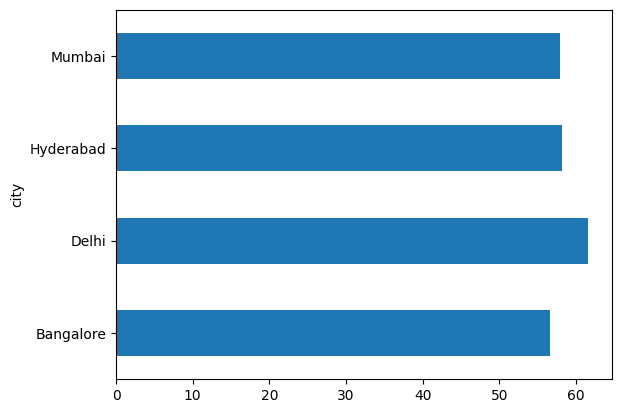

In [337]:
df.groupby('city')['occ_pct'].mean().plot(kind='barh')

**3.when was the occupancy better? weekday or weekend**

In [338]:
df.head(3)

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_class,property_name,category,city
0,16559,1-May-22,RT1,25,30.0,83.33,Standard,Atliq Exotica,Luxury,Mumbai
1,16559,2-May-22,RT1,20,30.0,66.67,Standard,Atliq Exotica,Luxury,Mumbai
2,16559,3-May-22,RT1,17,30.0,56.67,Standard,Atliq Exotica,Luxury,Mumbai


In [339]:
df_date.head(3)

,date,mmm yy,week no,day_type
0,01-May-22,May 22,W 19,weekend
1,02-May-22,May 22,W 19,weekeday
2,03-May-22,May 22,W 19,weekeday


In [340]:
df_date.head()

,date,mmm yy,week no,day_type
0,01-May-22,May 22,W 19,weekend
1,02-May-22,May 22,W 19,weekeday
2,03-May-22,May 22,W 19,weekeday
3,04-May-22,May 22,W 19,weekeday
4,05-May-22,May 22,W 19,weekeday


In [341]:
df = pd.merge(df,df_date,left_on='check_in_date',right_on='date')
df.head()

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_class,property_name,category,city,date,mmm yy,week no,day_type
0,16559,10-May-22,RT1,18,30.0,60.00,Standard,Atliq Exotica,Luxury,Mumbai,10-May-22,May 22,W 20,weekeday
1,16559,10-May-22,RT2,25,41.0,60.98,Elite,Atliq Exotica,Luxury,Mumbai,10-May-22,May 22,W 20,weekeday
2,16559,10-May-22,RT3,20,32.0,62.50,Premium,Atliq Exotica,Luxury,Mumbai,10-May-22,May 22,W 20,weekeday
3,16559,10-May-22,RT4,13,18.0,72.22,Presidential,Atliq Exotica,Luxury,Mumbai,10-May-22,May 22,W 20,weekeday
4,19562,10-May-22,RT1,18,30.0,60.00,Standard,Atliq Bay,Luxury,Bangalore,10-May-22,May 22,W 20,weekeday


In [342]:
df.groupby('day_type')['occ_pct'].mean()

,occ_pct
day_type,
weekeday,50.903780
weekend,72.393432


**4.in the month of june what is the occupancy for diffrent cities**

In [343]:
df['mmm yy'].unique()

array(['May 22', 'Jun 22', 'Jul 22'], dtype=object)

In [344]:
df_june_22 = df[df['mmm yy'] == 'Jun 22']
df_june_22.head()

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_class,property_name,category,city,date,mmm yy,week no,day_type
2200,16559,10-Jun-22,RT1,20,30.0,66.67,Standard,Atliq Exotica,Luxury,Mumbai,10-Jun-22,Jun 22,W 24,weekeday
2201,16559,10-Jun-22,RT2,26,41.0,63.41,Elite,Atliq Exotica,Luxury,Mumbai,10-Jun-22,Jun 22,W 24,weekeday
2202,16559,10-Jun-22,RT3,20,32.0,62.50,Premium,Atliq Exotica,Luxury,Mumbai,10-Jun-22,Jun 22,W 24,weekeday
2203,16559,10-Jun-22,RT4,11,18.0,61.11,Presidential,Atliq Exotica,Luxury,Mumbai,10-Jun-22,Jun 22,W 24,weekeday
2204,19562,10-Jun-22,RT1,19,30.0,63.33,Standard,Atliq Bay,Luxury,Bangalore,10-Jun-22,Jun 22,W 24,weekeday


In [345]:
df_june_22.groupby('city')['occ_pct'].mean().round(2).sort_values(ascending=False)

,occ_pct
city,
Delhi,62.47
Hyderabad,58.46
Mumbai,58.38
Bangalore,56.58


<Axes: xlabel='city'>

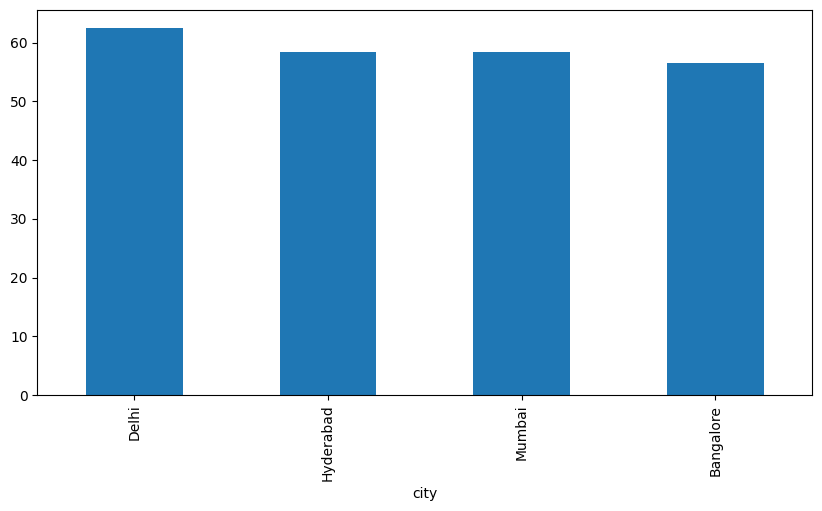

In [346]:
df_june_22.groupby('city')['occ_pct'].mean().round(2).sort_values(ascending=False).plot(kind='bar',figsize=(10,5))

**5.we got new data for the month of august,Append that to existing data**

In [347]:
df_august = pd.read_csv('datasets/new_data_august.csv')
df_august.head()

,property_id,property_name,category,city,room_category,room_class,check_in_date,mmm yy,week no,day_type,successful_bookings,capacity,occ%
0,16559,Atliq Exotica,Luxury,Mumbai,RT1,Standard,01-Aug-22,Aug-22,W 32,weekeday,30,30,100.00
1,19562,Atliq Bay,Luxury,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekeday,21,30,70.00
2,19563,Atliq Palace,Business,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekeday,23,30,76.67
3,19558,Atliq Grands,Luxury,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekeday,30,40,75.00
4,19560,Atliq City,Business,Bangalore,RT1,Standard,01-Aug-22,Aug-22,W 32,weekeday,20,26,76.92


In [348]:
df_august.columns

Index(['property_id', 'property_name', 'category', 'city', 'room_category',
       'room_class', 'check_in_date', 'mmm yy', 'week no', 'day_type',
       'successful_bookings', 'capacity', 'occ%'],
      dtype='object')

In [349]:
df_august.shape

(7, 13)

In [350]:
df.shape

(6500, 14)

In [351]:
latest_df = pd.concat([df,df_august],ignore_index=True,axis=0)
latest_df.tail(10)

,property_id,check_in_date,room_category,successful_bookings,capacity,occ_pct,room_class,property_name,category,city,date,mmm yy,week no,day_type,occ%
6497,18560,31-Jul-22,RT2,34,40.0,85.00,Elite,Atliq City,Business,Hyderabad,31-Jul-22,Jul 22,W 32,weekend,NaN
6498,18560,31-Jul-22,RT3,17,24.0,70.83,Premium,Atliq City,Business,Hyderabad,31-Jul-22,Jul 22,W 32,weekend,NaN
6499,18560,31-Jul-22,RT4,12,15.0,80.00,Presidential,Atliq City,Business,Hyderabad,31-Jul-22,Jul 22,W 32,weekend,NaN
6500,16559,01-Aug-22,RT1,30,30.0,NaN,Standard,Atliq Exotica,Luxury,Mumbai,NaN,Aug-22,W 32,weekeday,100.00
6501,19562,01-Aug-22,RT1,21,30.0,NaN,Standard,Atliq Bay,Luxury,Bangalore,NaN,Aug-22,W 32,weekeday,70.00
6502,19563,01-Aug-22,RT1,23,30.0,NaN,Standard,Atliq Palace,Business,Bangalore,NaN,Aug-22,W 32,weekeday,76.67
6503,19558,01-Aug-22,RT1,30,40.0,NaN,Standard,Atliq Grands,Luxury,Bangalore,NaN,Aug-22,W 32,weekeday,75.00
6504,19560,01-Aug-22,RT1,20,26.0,NaN,Standard,Atliq City,Business,Bangalore,NaN,Aug-22,W 32,weekeday,76.92
6505,17561,01-Aug-22,RT1,18,26.0,NaN,Standard,Atliq Blu,Luxury,Mumbai,NaN,Aug-22,W 32,weekeday,69.23
6506,17564,01-Aug-22,RT1,10,16.0,NaN,Standard,Atliq Seasons,Business,Mumbai,NaN,Aug-22,W 32,weekeday,62.50


In [352]:
latest_df.shape

(6507, 15)

**6.revenue realized per city**

In [353]:
df_bookings.head(3)

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
1,May012216558RT12,16558,30-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640
4,May012216558RT15,16558,27-04-22,1/5/2022,2/5/2022,4.0,RT1,direct online,5.0,Checked Out,10920,10920
5,May012216558RT16,16558,1/5/2022,1/5/2022,3/5/2022,2.0,RT1,others,4.0,Checked Out,9100,9100


In [354]:
df_hotels.head(3)

,property_id,property_name,category,city
0,16558,Atliq Grands,Luxury,Delhi
1,16559,Atliq Exotica,Luxury,Mumbai
2,16560,Atliq City,Business,Delhi


In [355]:
df_bookings_all = pd.merge(df_bookings,df_hotels,on='property_id')
df_bookings_all.head()

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city
0,May012216558RT12,16558,30-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi
1,May012216558RT15,16558,27-04-22,1/5/2022,2/5/2022,4.0,RT1,direct online,5.0,Checked Out,10920,10920,Atliq Grands,Luxury,Delhi
2,May012216558RT16,16558,1/5/2022,1/5/2022,3/5/2022,2.0,RT1,others,4.0,Checked Out,9100,9100,Atliq Grands,Luxury,Delhi
3,May012216558RT17,16558,28-04-22,1/5/2022,6/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi
4,May012216558RT18,16558,26-04-22,1/5/2022,3/5/2022,2.0,RT1,logtrip,NaN,No Show,9100,9100,Atliq Grands,Luxury,Delhi


In [356]:
data = df_bookings_all.groupby('city')['revenue_realized'].sum()
data

,revenue_realized
city,
Bangalore,420383550
Delhi,294404488
Hyderabad,325179310
Mumbai,668569251


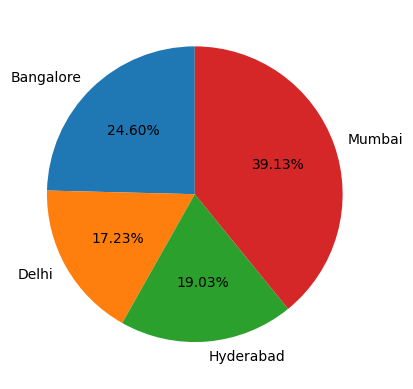

In [357]:
import matplotlib.pyplot as plt
plt.pie(data,labels = data.index,autopct='%.2f%%',startangle=90)
plt.show()

**7.print month by month revenue**

In [358]:
df_date.head(3)

,date,mmm yy,week no,day_type
0,01-May-22,May 22,W 19,weekend
1,02-May-22,May 22,W 19,weekeday
2,03-May-22,May 22,W 19,weekeday


In [359]:
df_date['mmm yy'].unique()

array(['May 22', 'Jun 22', 'Jul 22'], dtype=object)

In [360]:
df_bookings_all.head(3)

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city
0,May012216558RT12,16558,30-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi
1,May012216558RT15,16558,27-04-22,1/5/2022,2/5/2022,4.0,RT1,direct online,5.0,Checked Out,10920,10920,Atliq Grands,Luxury,Delhi
2,May012216558RT16,16558,1/5/2022,1/5/2022,3/5/2022,2.0,RT1,others,4.0,Checked Out,9100,9100,Atliq Grands,Luxury,Delhi


In [361]:
pd.merge(df_bookings_all,df_date,left_on='check_in_date',right_on='date')

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city,date,mmm yy,week no,day_type


In [362]:
df_bookings_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134573 entries, 0 to 134572
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   booking_id         134573 non-null  object 
 1   property_id        134573 non-null  int64  
 2   booking_date       134573 non-null  object 
 3   check_in_date      134573 non-null  object 
 4   checkout_date      134573 non-null  object 
 5   no_guests          134573 non-null  float64
 6   room_category      134573 non-null  object 
 7   booking_platform   134573 non-null  object 
 8   ratings_given      56676 non-null   float64
 9   booking_status     134573 non-null  object 
 10  revenue_generated  134573 non-null  int64  
 11  revenue_realized   134573 non-null  int64  
 12  property_name      134573 non-null  object 
 13  category           134573 non-null  object 
 14  city               134573 non-null  object 
dtypes: float64(2), int64(3), object(10)
memory usage: 1

In [363]:
df_date.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   date      92 non-null     object
 1   mmm yy    92 non-null     object
 2   week no   92 non-null     object
 3   day_type  92 non-null     object
dtypes: object(4)
memory usage: 3.0+ KB


In [364]:
df_date['date'] = pd.to_datetime(df_date['date'])
df_date.head(3)

<ipython-input-364-2feb6b41758a>:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_date['date'] = pd.to_datetime(df_date['date'])


,date,mmm yy,week no,day_type
0,2022-05-01,May 22,W 19,weekend
1,2022-05-02,May 22,W 19,weekeday
2,2022-05-03,May 22,W 19,weekeday


In [365]:
df_date.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      92 non-null     datetime64[ns]
 1   mmm yy    92 non-null     object        
 2   week no   92 non-null     object        
 3   day_type  92 non-null     object        
dtypes: datetime64[ns](1), object(3)
memory usage: 3.0+ KB


In [366]:
df_bookings_all['check_in_date'] = pd.to_datetime(df_bookings_all['check_in_date'],dayfirst=True,errors='coerce')
df_bookings_all.head(3)

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city
0,May012216558RT12,16558,30-04-22,2022-05-01,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi
1,May012216558RT15,16558,27-04-22,2022-05-01,2/5/2022,4.0,RT1,direct online,5.0,Checked Out,10920,10920,Atliq Grands,Luxury,Delhi
2,May012216558RT16,16558,1/5/2022,2022-05-01,3/5/2022,2.0,RT1,others,4.0,Checked Out,9100,9100,Atliq Grands,Luxury,Delhi


In [367]:
df_bookings_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134573 entries, 0 to 134572
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   booking_id         134573 non-null  object        
 1   property_id        134573 non-null  int64         
 2   booking_date       134573 non-null  object        
 3   check_in_date      55790 non-null   datetime64[ns]
 4   checkout_date      134573 non-null  object        
 5   no_guests          134573 non-null  float64       
 6   room_category      134573 non-null  object        
 7   booking_platform   134573 non-null  object        
 8   ratings_given      56676 non-null   float64       
 9   booking_status     134573 non-null  object        
 10  revenue_generated  134573 non-null  int64         
 11  revenue_realized   134573 non-null  int64         
 12  property_name      134573 non-null  object        
 13  category           134573 non-null  object  

In [368]:
df_bookings_all = pd.merge(df_bookings_all,df_date,left_on='check_in_date',right_on='date')
df_bookings_all.head()

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city,date,mmm yy,week no,day_type
0,May012216558RT12,16558,30-04-22,2022-05-01,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi,2022-05-01,May 22,W 19,weekend
1,May012216558RT15,16558,27-04-22,2022-05-01,2/5/2022,4.0,RT1,direct online,5.0,Checked Out,10920,10920,Atliq Grands,Luxury,Delhi,2022-05-01,May 22,W 19,weekend
2,May012216558RT16,16558,1/5/2022,2022-05-01,3/5/2022,2.0,RT1,others,4.0,Checked Out,9100,9100,Atliq Grands,Luxury,Delhi,2022-05-01,May 22,W 19,weekend
3,May012216558RT17,16558,28-04-22,2022-05-01,6/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi,2022-05-01,May 22,W 19,weekend
4,May012216558RT18,16558,26-04-22,2022-05-01,3/5/2022,2.0,RT1,logtrip,NaN,No Show,9100,9100,Atliq Grands,Luxury,Delhi,2022-05-01,May 22,W 19,weekend


In [369]:
df_bookings_all.groupby('mmm yy')['revenue_realized'].sum()

,revenue_realized
mmm yy,
Jul 22,243180932
Jun 22,229637640
May 22,234353183


#**Revenue Analysis**

In [370]:
dim_hotels = pd.read_csv('datasets/dim_hotels.csv')
fact_bookings = pd.read_csv('datasets/fact_bookings.csv')

In [371]:
revenue_df = pd.merge(fact_bookings,dim_hotels,on='property_id',how='left')
revenue_df.head()

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city
0,May012216558RT11,16558,27-04-22,1/5/2022,2/5/2022,-3.0,RT1,direct online,1.0,Checked Out,10010,10010,Atliq Grands,Luxury,Delhi
1,May012216558RT12,16558,30-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi
2,May012216558RT13,16558,28-04-22,1/5/2022,4/5/2022,2.0,RT1,logtrip,5.0,Checked Out,9100000,9100,Atliq Grands,Luxury,Delhi
3,May012216558RT14,16558,28-04-22,1/5/2022,2/5/2022,-2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi
4,May012216558RT15,16558,27-04-22,1/5/2022,2/5/2022,4.0,RT1,direct online,5.0,Checked Out,10920,10920,Atliq Grands,Luxury,Delhi


**calculate hotel wise revenue**

In [372]:
hotel_revenue = revenue_df.groupby(['property_name','city']).agg({'revenue_realized':'sum'}).rename(columns={'revenue_realized':'total_revenue(Millions)'}).reset_index()
hotel_revenue['total_revenue(Millions)'] = hotel_revenue['total_revenue(Millions)']/1000000
hotel_revenue['total_revenue(Millions)']= hotel_revenue['total_revenue(Millions)'].round(2)
hotel_revenue

,property_name,city,total_revenue(Millions)
0,Atliq Bay,Bangalore,82.44
1,Atliq Bay,Delhi,56.44
2,Atliq Bay,Hyderabad,69.26
3,Atliq Bay,Mumbai,51.91
4,Atliq Blu,Bangalore,72.96
5,Atliq Blu,Delhi,57.93
6,Atliq Blu,Hyderabad,56.04
7,Atliq Blu,Mumbai,73.92
8,Atliq City,Bangalore,81.88
9,Atliq City,Delhi,54.93


In [373]:
revenue_pivot = hotel_revenue.pivot(index='city',columns='property_name',values='total_revenue(Millions)')
revenue_pivot

property_name,Atliq Bay,Atliq Blu,Atliq City,Atliq Exotica,Atliq Grands,Atliq Palace,Atliq Seasons
city,,,,,,,
Bangalore,82.44,72.96,81.88,60.02,54.49,68.60,NaN
Delhi,56.44,57.93,54.93,NaN,36.06,89.14,NaN
Hyderabad,69.26,56.04,61.01,47.84,46.25,44.84,NaN
Mumbai,51.91,73.92,88.00,212.44,74.73,101.51,66.13


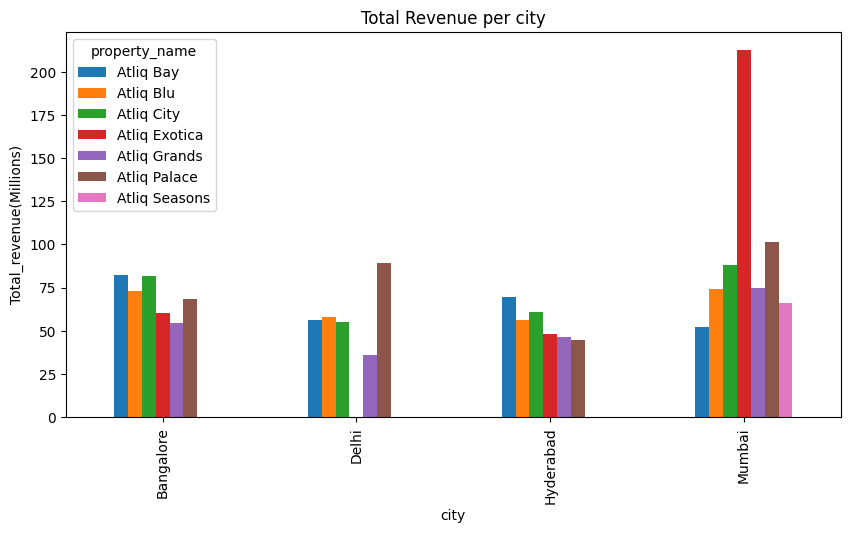

In [374]:
revenue_pivot.plot(kind='bar',figsize=(10,5),)
plt.ylabel('Total_revenue(Millions)')
plt.title('Total Revenue per city')
plt.show()

**citywise revenue**

In [375]:
city_revenue = revenue_df.groupby(['city']).agg({'revenue_realized':'sum'}).rename(columns={'revenue_realized':'total_revenue(Millions)'}).reset_index()
city_revenue['total_revenue(Millions)'] = city_revenue['total_revenue(Millions)']/1000000
city_revenue['total_revenue(Millions)']= city_revenue['total_revenue(Millions)'].round(2)
city_revenue.sort_values('total_revenue(Millions)',ascending=False)

,city,total_revenue(Millions)
3,Mumbai,668.64
0,Bangalore,420.40
2,Hyderabad,325.23
1,Delhi,294.50


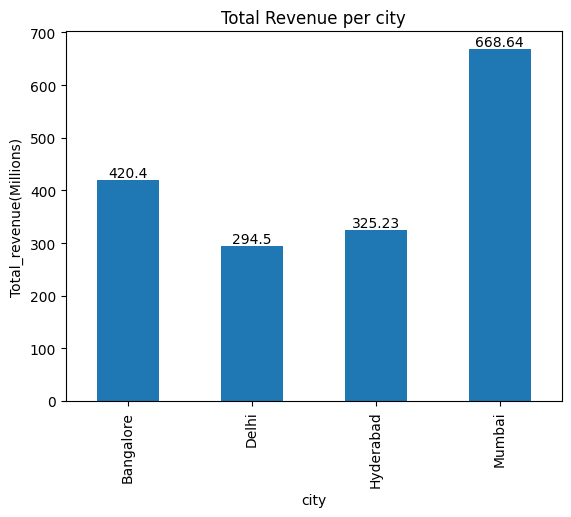

In [376]:
plot = city_revenue.plot(kind='bar',x='city',y='total_revenue(Millions)',legend=False)
plt.ylabel('Total_revenue(Millions)')
plt.title('Total Revenue per city')

for index,value in enumerate(city_revenue['total_revenue(Millions)']):
  plot.text(index,value,str(value),ha='center',va='bottom')
plt.show()

**revenue per week**

In [377]:
dim_date = pd.read_csv('datasets/dim_date.csv')
dim_date.head(4)

,date,mmm yy,week no,day_type
0,01-May-22,May 22,W 19,weekend
1,02-May-22,May 22,W 19,weekeday
2,03-May-22,May 22,W 19,weekeday
3,04-May-22,May 22,W 19,weekeday


In [378]:
revenue_df = pd.merge(fact_bookings,dim_hotels,on='property_id',how='left')
revenue_df.head()

,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized,property_name,category,city
0,May012216558RT11,16558,27-04-22,1/5/2022,2/5/2022,-3.0,RT1,direct online,1.0,Checked Out,10010,10010,Atliq Grands,Luxury,Delhi
1,May012216558RT12,16558,30-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi
2,May012216558RT13,16558,28-04-22,1/5/2022,4/5/2022,2.0,RT1,logtrip,5.0,Checked Out,9100000,9100,Atliq Grands,Luxury,Delhi
3,May012216558RT14,16558,28-04-22,1/5/2022,2/5/2022,-2.0,RT1,others,NaN,Cancelled,9100,3640,Atliq Grands,Luxury,Delhi
4,May012216558RT15,16558,27-04-22,1/5/2022,2/5/2022,4.0,RT1,direct online,5.0,Checked Out,10920,10920,Atliq Grands,Luxury,Delhi


In [379]:
revenue_week = pd.merge(dim_date,revenue_df,how='left',left_on='date',right_on='check_in_date')
revenue_data = revenue_week.groupby(['week no','property_name']).agg({'revenue_realized':'sum'}).rename(columns={'revenue_realized':'total_revenue(Millions)'}).reset_index()
revenue_data['total_revenue(Millions)'] = revenue_data['total_revenue(Millions)']/1000000
revenue_data['total_revenue(Millions)']= revenue_data['total_revenue(Millions)'].round(2)
revenue_data

,week no,property_name,total_revenue(Millions)


In [380]:
print(revenue_week.head())
print(revenue_week.info())

        date  mmm yy week no  day_type booking_id  property_id booking_date  \
0  01-May-22  May 22    W 19   weekend        NaN          NaN          NaN   
1  02-May-22  May 22    W 19  weekeday        NaN          NaN          NaN   
2  03-May-22  May 22    W 19  weekeday        NaN          NaN          NaN   
3  04-May-22  May 22    W 19  weekeday        NaN          NaN          NaN   
4  05-May-22  May 22    W 19  weekeday        NaN          NaN          NaN   

  check_in_date checkout_date  no_guests room_category booking_platform  \
0           NaN           NaN        NaN           NaN              NaN   
1           NaN           NaN        NaN           NaN              NaN   
2           NaN           NaN        NaN           NaN              NaN   
3           NaN           NaN        NaN           NaN              NaN   
4           NaN           NaN        NaN           NaN              NaN   

   ratings_given booking_status  revenue_generated  revenue_realized  \
0 

In [381]:
print(dim_date['date'].head())
print(revenue_df['check_in_date'].head())

0    01-May-22
1    02-May-22
2    03-May-22
3    04-May-22
4    05-May-22
Name: date, dtype: object
0    1/5/2022
1    1/5/2022
2    1/5/2022
3    1/5/2022
4    1/5/2022
Name: check_in_date, dtype: object


In [382]:
common_data = dim_date['date'].isin(revenue_df['check_in_date'])
common_data.sum()

0

In [383]:
dim_date['date'] = pd.to_datetime(dim_date['date'],dayfirst=True,errors='coerce')
revenue_df['check_in_date'] = pd.to_datetime(revenue_df['check_in_date'],dayfirst=True,errors='coerce')

<ipython-input-383-cbbf2933ff4c>:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dim_date['date'] = pd.to_datetime(dim_date['date'],dayfirst=True,errors='coerce')


In [384]:
revenue_week = pd.merge(dim_date,revenue_df,how='left',left_on='date',right_on='check_in_date')
print(revenue_week.head())
print(revenue_week.info())

        date  mmm yy week no day_type        booking_id  property_id  \
0 2022-05-01  May 22    W 19  weekend  May012216558RT11      16558.0   
1 2022-05-01  May 22    W 19  weekend  May012216558RT12      16558.0   
2 2022-05-01  May 22    W 19  weekend  May012216558RT13      16558.0   
3 2022-05-01  May 22    W 19  weekend  May012216558RT14      16558.0   
4 2022-05-01  May 22    W 19  weekend  May012216558RT15      16558.0   

  booking_date check_in_date checkout_date  no_guests room_category  \
0     27-04-22    2022-05-01      2/5/2022       -3.0           RT1   
1     30-04-22    2022-05-01      2/5/2022        2.0           RT1   
2     28-04-22    2022-05-01      4/5/2022        2.0           RT1   
3     28-04-22    2022-05-01      2/5/2022       -2.0           RT1   
4     27-04-22    2022-05-01      2/5/2022        4.0           RT1   

  booking_platform  ratings_given booking_status  revenue_generated  \
0    direct online            1.0    Checked Out            10010.0  

In [385]:
revenue_week = pd.merge(dim_date,revenue_df,how='left',left_on='date',right_on='check_in_date')
revenue_data = revenue_week.groupby(['week no','property_name']).agg({'revenue_realized':'sum'}).rename(columns={'revenue_realized':'total_revenue(Millions)'}).reset_index()
revenue_data['total_revenue(Millions)'] = revenue_data['total_revenue(Millions)']/1000000
revenue_data['total_revenue(Millions)']= revenue_data['total_revenue(Millions)'].round(2)
revenue_data.head()

,week no,property_name,total_revenue(Millions)
0,W 19,Atliq Bay,20.87
1,W 19,Atliq Blu,20.98
2,W 19,Atliq City,23.32
3,W 19,Atliq Exotica,25.74
4,W 19,Atliq Grands,17.55


**weely hotelwise revenue trend**

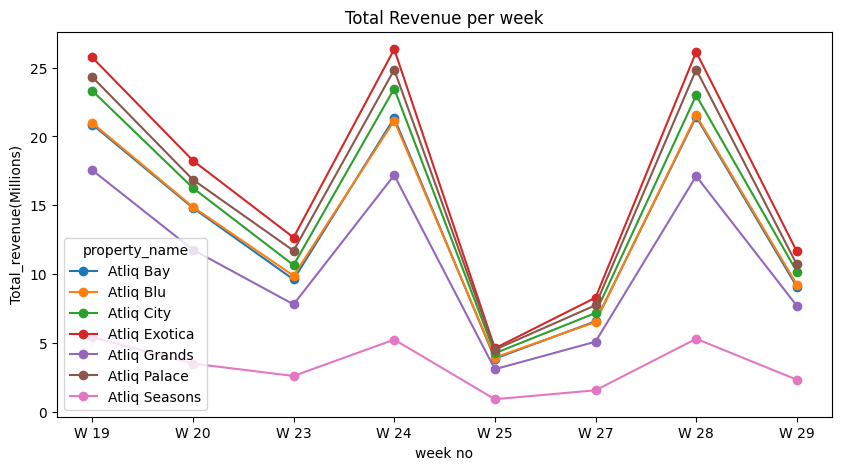

In [386]:
weekly_revenue = revenue_data.pivot(index='week no',columns='property_name',values='total_revenue(Millions)')
weekly_revenue.plot(kind='line',figsize=(10,5),marker='o')
plt.ylabel('Total_revenue(Millions)')
plt.title('Total Revenue per week')
plt.show()


**check revenue trend week over week**

In [387]:
revenue_trend_ww = revenue_data.groupby(['week no']).agg({'total_revenue(Millions)':'sum'}).reset_index()
revenue_trend_ww['last week rev'] = revenue_trend_ww['total_revenue(Millions)'].shift(1)
revenue_trend_ww['Chang Percentage'] = ((revenue_trend_ww['total_revenue(Millions)']/revenue_trend_ww['last week rev'])-1)*100
revenue_trend_ww['revenue_diff'] = revenue_trend_ww['total_revenue(Millions)'] - revenue_trend_ww['last week rev']

revenue_trend_ww

,week no,total_revenue(Millions),last week rev,Chang Percentage,revenue_diff
0,W 19,138.19,NaN,NaN,NaN
1,W 20,96.33,138.19,-30.291627,-41.86
2,W 23,64.90,96.33,-32.627427,-31.43
3,W 24,139.59,64.90,115.084746,74.69
4,W 25,25.17,139.59,-81.968622,-114.42
5,W 27,42.94,25.17,70.599921,17.77
6,W 28,139.37,42.94,224.569166,96.43
7,W 29,60.88,139.37,-56.317715,-78.49


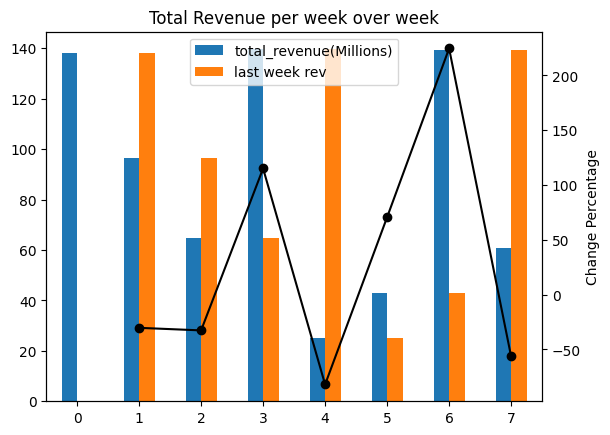

In [388]:
revenue_trend_ww[['total_revenue(Millions)','last week rev']].plot(kind='bar')
revenue_trend_ww['Chang Percentage'].plot(secondary_y=True,color='black',marker='o')
plt.ylabel('Change Percentage')
plt.title('Total Revenue per week over week')
plt.show()

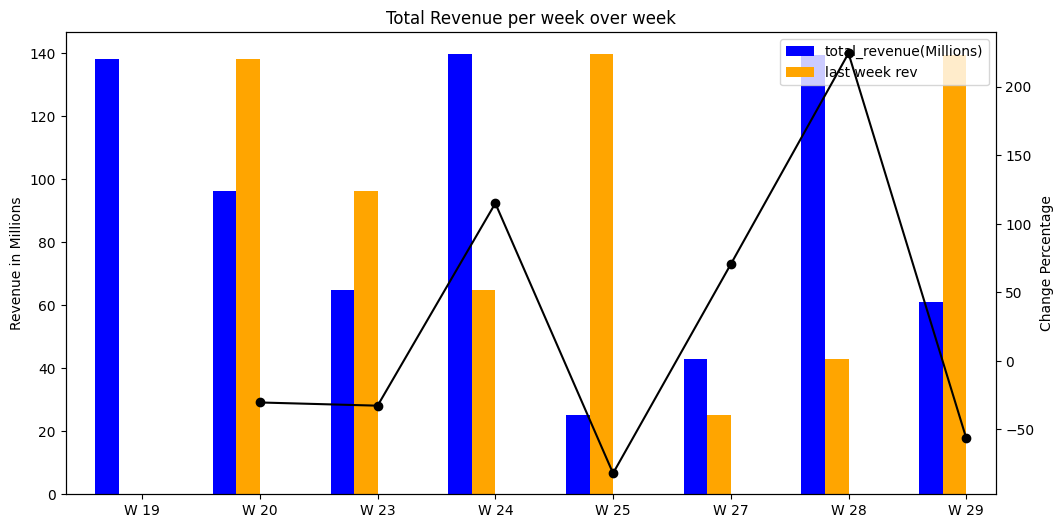

In [389]:
plt.figure(figsize=(12,6))
ax = revenue_trend_ww[['total_revenue(Millions)','last week rev']].plot(kind='bar',width=0.4,position=1,ax=plt.gca(),color=['blue','orange'])
revenue_trend_ww['Chang Percentage'].plot(secondary_y=True,color='black',marker='o',ax=ax)
ax.set_xticks(range(len(revenue_trend_ww)))
ax.set_xticklabels(revenue_trend_ww['week no'])
ax.set_ylabel('Revenue in Millions')
ax.right_ax.set_ylabel('Change Percentage')
plt.title('Total Revenue per week over week')
plt.show()

**Booking Analysis**

In [390]:
#hotel wise bookings
hotel_bookings = revenue_df.groupby(['property_name','city']).agg({'booking_id':'count'}).rename(columns={'booking_id':'total_bookings'}).reset_index()
hotel_bookings.head(10)

,property_name,city,total_bookings
0,Atliq Bay,Bangalore,5812
1,Atliq Bay,Delhi,4820
2,Atliq Bay,Hyderabad,7333
3,Atliq Bay,Mumbai,3424
4,Atliq Blu,Bangalore,5736
5,Atliq Blu,Delhi,4418
6,Atliq Blu,Hyderabad,6458
7,Atliq Blu,Mumbai,5183
8,Atliq City,Bangalore,5979
9,Atliq City,Delhi,4693


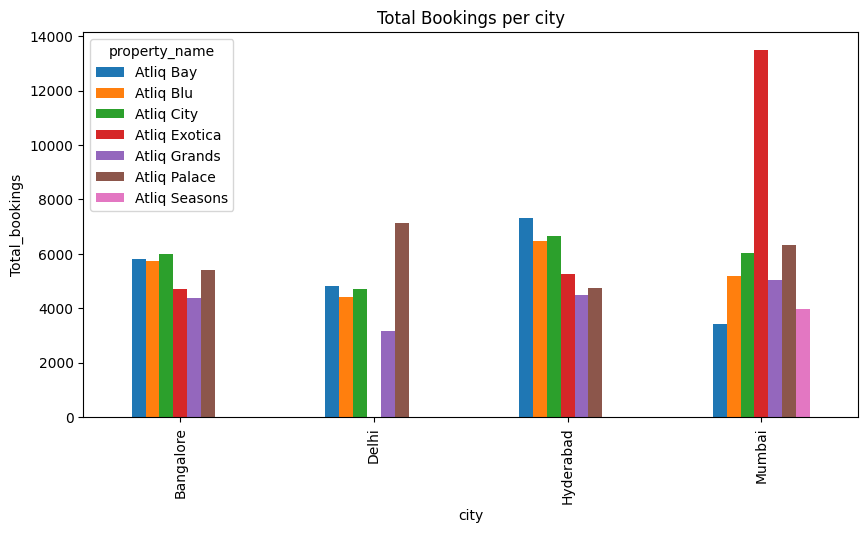

In [391]:
booking_pivot = hotel_bookings.pivot(index='city',columns='property_name',values='total_bookings')
booking_pivot.plot(kind='bar',figsize=(10,5))
plt.ylabel('Total_bookings')
plt.title('Total Bookings per city')
plt.show()

**hotel wise cancellation percentage,check out percentage,no show percentage**

In [392]:
data = revenue_df.groupby(['property_name','booking_status']).agg({'booking_id':'count'}).rename(columns={'booking_id':'total_bookings'}).reset_index()
data1 = revenue_df.groupby(['property_name']).agg({'booking_id':'count'}).rename(columns={'booking_id':'total_bookings'}).reset_index()
data3 = data.pivot(index='property_name',columns='booking_status',values='total_bookings')
data4 = pd.merge(data1,data3,on='property_name')
data4

,property_name,total_bookings,Cancelled,Checked Out,No Show
0,Atliq Bay,21389,5314,14965,1110
1,Atliq Blu,21795,5373,15267,1155
2,Atliq City,23323,5811,16365,1147
3,Atliq Exotica,23441,5713,16557,1171
4,Atliq Grands,17035,4273,11914,848
5,Atliq Palace,23625,5949,16532,1144
6,Atliq Seasons,3982,987,2811,184


In [393]:
data4['cancel_perc'] = (data4['Cancelled']/data4['total_bookings'])*100
data4['check_out_perc'] = (data4['Checked Out']/data4['total_bookings'])*100
data4['no_show_perc'] = (data4['No Show']/data4['total_bookings'])*100
data5 = data4[['property_name','cancel_perc','check_out_perc','no_show_perc']]
data5

,property_name,cancel_perc,check_out_perc,no_show_perc
0,Atliq Bay,24.844546,69.965870,5.189583
1,Atliq Blu,24.652443,70.048176,5.299381
2,Atliq City,24.915320,70.166788,4.917892
3,Atliq Exotica,24.371827,70.632652,4.995521
4,Atliq Grands,25.083651,69.938362,4.977986
5,Atliq Palace,25.180952,69.976720,4.842328
6,Atliq Seasons,24.786539,70.592667,4.620794


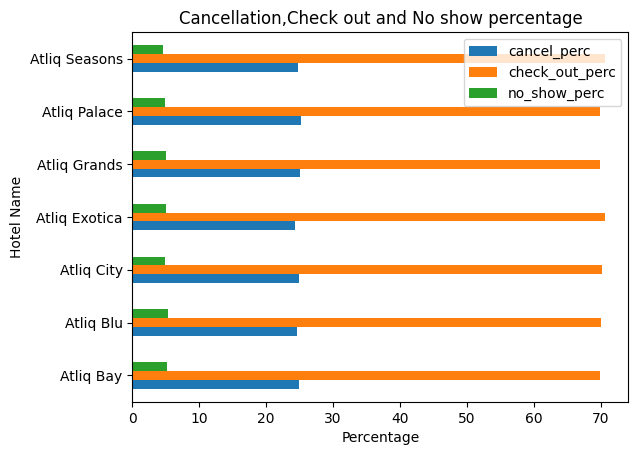

In [394]:
data5.plot(kind='barh',x='property_name')
plt.ylabel('Hotel Name')
plt.xlabel('Percentage')
plt.title('Cancellation,Check out and No show percentage')
plt.show()

**platform wise booking**

In [395]:
#pf_booking = revenue_df.groupby(['booking_platform']).agg({'booking_id':'count'}).rename(columns={'booking_id':'total_bookings'}).reset_index()
pf_booking = df_bookings.booking_platform.value_counts()
pf_booking

,count
booking_platform,
others,55061
makeyourtrip,26896
logtrip,14753
direct online,13374
tripster,9630
journey,8106
direct offline,6753


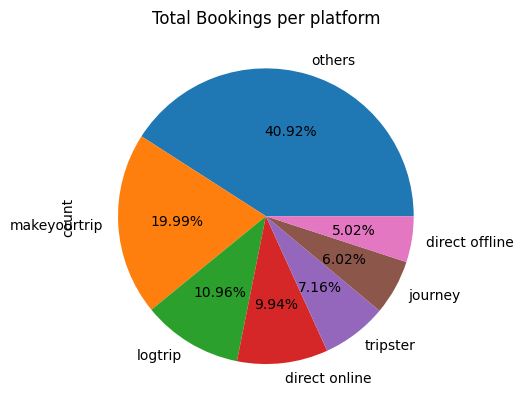

In [396]:
pf_booking.plot(kind='pie',autopct='%.2f%%')
plt.title('Total Bookings per platform')
plt.show()


**room catagerywise booking**

In [397]:
dim_rooms = pd.read_csv('datasets/dim_rooms.csv')
rooms_data = pd.merge(dim_rooms,fact_bookings,how='left',left_on='room_id',right_on='room_category')
rooms_data.head()


,room_id,room_class,booking_id,property_id,booking_date,check_in_date,checkout_date,no_guests,room_category,booking_platform,ratings_given,booking_status,revenue_generated,revenue_realized
0,RT1,Standard,May012216558RT11,16558,27-04-22,1/5/2022,2/5/2022,-3.0,RT1,direct online,1.0,Checked Out,10010,10010
1,RT1,Standard,May012216558RT12,16558,30-04-22,1/5/2022,2/5/2022,2.0,RT1,others,NaN,Cancelled,9100,3640
2,RT1,Standard,May012216558RT13,16558,28-04-22,1/5/2022,4/5/2022,2.0,RT1,logtrip,5.0,Checked Out,9100000,9100
3,RT1,Standard,May012216558RT14,16558,28-04-22,1/5/2022,2/5/2022,-2.0,RT1,others,NaN,Cancelled,9100,3640
4,RT1,Standard,May012216558RT15,16558,27-04-22,1/5/2022,2/5/2022,4.0,RT1,direct online,5.0,Checked Out,10920,10920


In [398]:
room_bookings = rooms_data.groupby(['room_class']).agg({'booking_id':'count'})
room_bookings['Percentage'] = (room_bookings['booking_id']/room_bookings['booking_id'].sum())*100
room_bookings['Percentage'] = room_bookings['Percentage'].round(2)
room_bookings

,booking_id,Percentage
room_class,,
Elite,49505,36.78
Premium,30566,22.71
Presidential,16073,11.94
Standard,38446,28.57


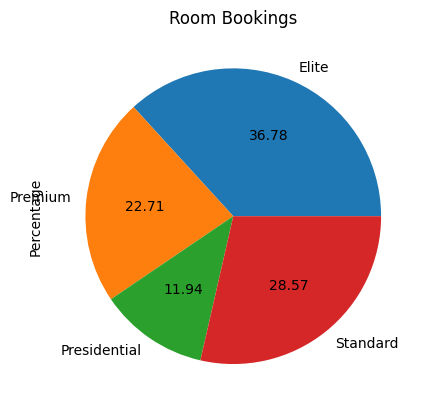

In [399]:
room_bookings['Percentage'].plot(kind='pie',autopct='%.2f')
plt.title('Room Bookings')
plt.show()

#**Occupancy Analysis**

In [400]:
fact_agg = pd.read_csv('datasets/fact_aggregated_bookings.csv')
fact_agg.head()

,property_id,check_in_date,room_category,successful_bookings,capacity
0,16559,1-May-22,RT1,25,30.0
1,19562,1-May-22,RT1,28,30.0
2,19563,1-May-22,RT1,23,30.0
3,17558,1-May-22,RT1,30,19.0
4,16558,1-May-22,RT1,18,19.0


In [401]:
# occ = pd.merge(dim_hotels,fact_agg,on='property_id',how='left')
# occ.head()

occ = pd.merge(dim_hotels,fact_agg,on='property_id',how='left')
occ['check_in_date'] = pd.to_datetime(occ['check_in_date'],errors='coerce')
dim_date['date'] = pd.to_datetime(dim_date['date'],errors='coerce')
occ_df = pd.merge(dim_date,occ,how='left',left_on='date',right_on='check_in_date')
occ.head()

<ipython-input-401-13157d4419e2>:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  occ['check_in_date'] = pd.to_datetime(occ['check_in_date'],errors='coerce')


,property_id,property_name,category,city,check_in_date,room_category,successful_bookings,capacity
0,16558,Atliq Grands,Luxury,Delhi,2022-05-01,RT1,18,19.0
1,16558,Atliq Grands,Luxury,Delhi,2022-05-01,RT2,21,22.0
2,16558,Atliq Grands,Luxury,Delhi,2022-05-01,RT3,8,8.0
3,16558,Atliq Grands,Luxury,Delhi,2022-05-01,RT4,3,3.0
4,16558,Atliq Grands,Luxury,Delhi,2022-05-02,RT1,12,19.0


**hotelwise occupancy**

In [402]:
hotel_occ = df.groupby(['city','property_name']).agg({'successful_bookings':'sum','capacity':'sum'}).reset_index()
hotel_occ['occupancy'] = (hotel_occ['successful_bookings']*100/hotel_occ['capacity']).round(2)
hotel_occ.head()

,city,property_name,successful_bookings,capacity,occupancy
0,Bangalore,Atliq Bay,4016,6240.0,64.36
1,Bangalore,Atliq Blu,3964,7605.0,52.12
2,Bangalore,Atliq City,4144,6435.0,64.40
3,Bangalore,Atliq Exotica,3284,6175.0,53.18
4,Bangalore,Atliq Grands,3061,6955.0,44.01


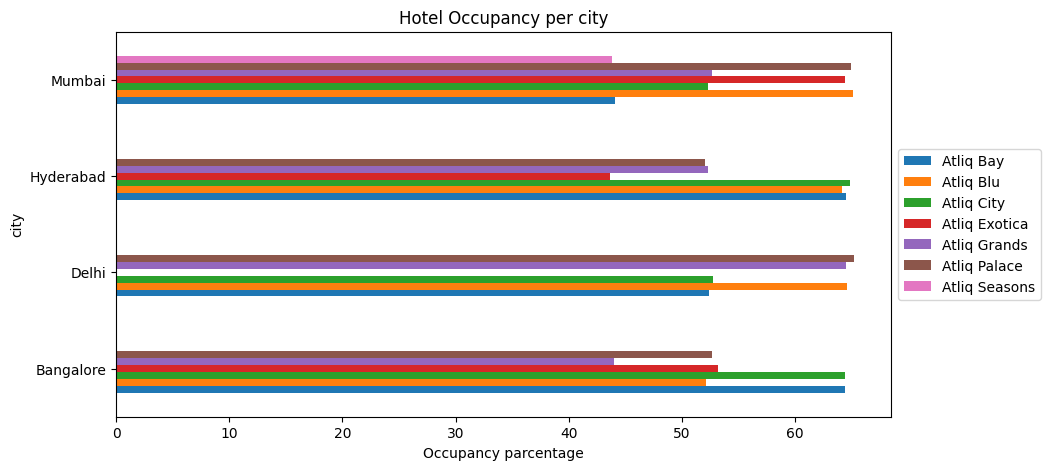

In [403]:
hotel_occ_pivot = hotel_occ.pivot(index='city',columns='property_name',values='occupancy')
hotel_occ_pivot.plot(kind='barh',figsize=(10,5))
plt.ylabel('city')
plt.xlabel('Occupancy parcentage')
plt.title('Hotel Occupancy per city')
plt.legend(loc='center left',bbox_to_anchor=(1,0.5))
plt.show()

**room class wise occupancy**

In [404]:
room_occ = pd.merge(dim_rooms,occ_df,how='left',left_on='room_id',right_on='room_category')
room_occ_df = room_occ.groupby(['room_class']).agg({'successful_bookings':'sum','capacity':'sum'})
room_occ_df['occupancy'] = room_occ_df['successful_bookings']*100/room_occ_df['capacity']
room_occ_df['occupancy'] = room_occ_df['occupancy'].round(2)
room_occ_df

,successful_bookings,capacity,occupancy
room_class,,,
Elite,49534,85928.0,57.65
Premium,30566,53084.0,57.58
Presidential,16082,27140.0,59.26
Standard,38651,66378.0,58.23


In [405]:
room_df = room_occ_df[['occupancy']]
room_df = room_df.sort_values(by='occupancy',ascending=False)
room_df

,occupancy
room_class,
Presidential,59.26
Standard,58.23
Elite,57.65
Premium,57.58


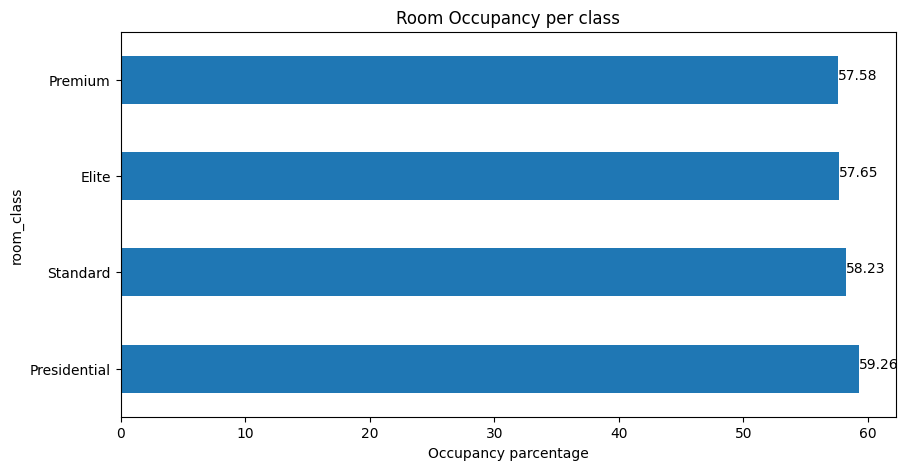

In [406]:
a = room_df.plot(kind='barh',figsize=(10,5),legend=False)
plt.xlabel('Occupancy parcentage')
plt.title('Room Occupancy per class')

for index,value in enumerate(room_df['occupancy']):
  a.text(value,index,str(value))
plt.show()

**daywise occupancy**

In [407]:
occ_df['Day'] = occ_df['date'].dt.day_name()
occ_df['Day No'] = occ_df['date'].dt.dayofweek
day_occ = occ_df.groupby(['Day','Day No','property_name']).agg({'successful_bookings':'sum','capacity':'sum'})
day_occ['occupancy'] = day_occ['successful_bookings']*100/day_occ['capacity']
day_occ['occupancy'] = day_occ['occupancy'].round(2)
day_occ = day_occ[['occupancy']]
data = day_occ.reset_index()
data = data.sort_values(by='Day No')
data.head()

,Day,Day No,property_name,occupancy
13,Monday,0,Atliq Seasons,38.62
7,Monday,0,Atliq Bay,51.82
8,Monday,0,Atliq Blu,55.62
9,Monday,0,Atliq City,52.69
10,Monday,0,Atliq Exotica,51.48


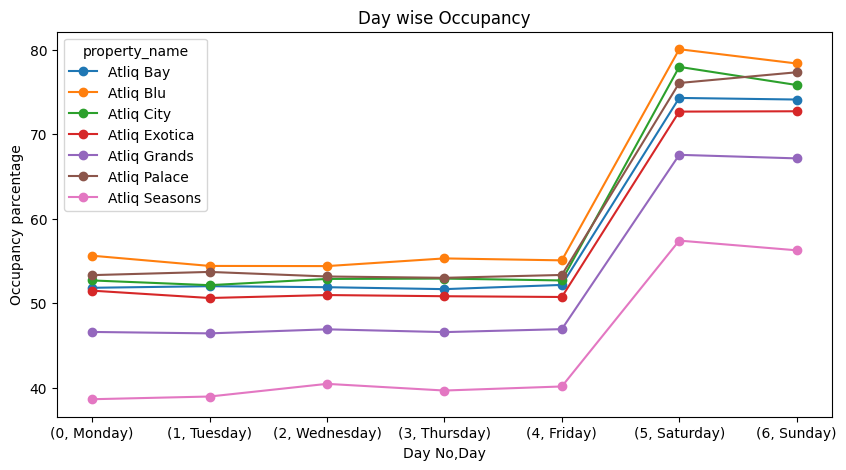

In [408]:
data_pivot = data.pivot(index=['Day No','Day'],columns=['property_name'],values='occupancy')
data_pivot.plot(kind='line',figsize=(10,5),marker='o')

plt.ylabel('Occupancy parcentage')
plt.title('Day wise Occupancy')
plt.show()


**week wise occupancy**

In [409]:
weekly_occ = occ_df.groupby(['week no','property_name']).agg({'successful_bookings':'sum','capacity':'sum'}).reset_index()
weekly_occ['occupancy'] = weekly_occ['successful_bookings']*100/weekly_occ['capacity']
weekly_occ['occupancy'] = weekly_occ['occupancy'].round(2)
weekly_occ

,week no,property_name,successful_bookings,capacity,occupancy
0,W 19,Atliq Bay,1745,2766.0,63.09
1,W 19,Atliq Blu,1771,2648.0,66.88
2,W 19,Atliq City,1897,2982.0,63.62
3,W 19,Atliq Exotica,1907,3115.0,61.22
4,W 19,Atliq Grands,1428,2464.0,57.95
...,...,...,...,...,...
93,W 32,Atliq City,291,426.0,68.31
94,W 32,Atliq Exotica,279,445.0,62.70
95,W 32,Atliq Grands,210,352.0,59.66
96,W 32,Atliq Palace,305,428.0,71.26


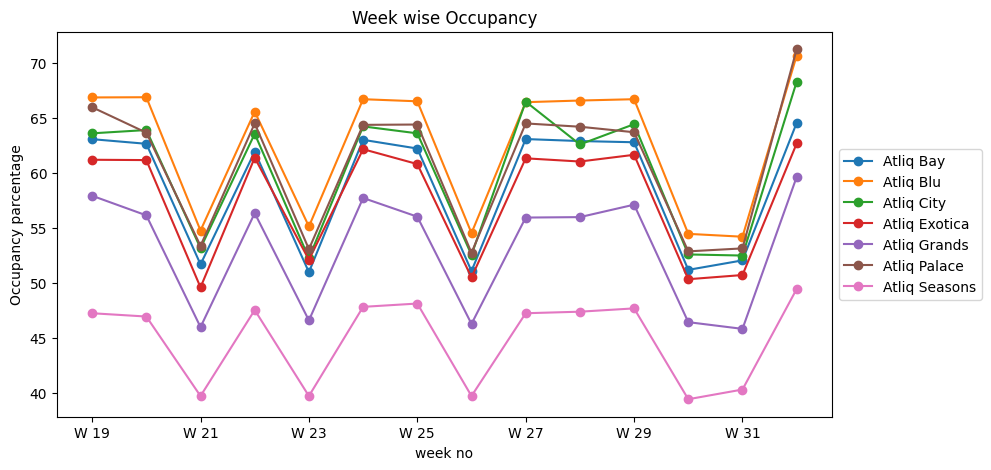

In [410]:
weekly_occ_pivot = weekly_occ.pivot(index='week no',columns='property_name',values='occupancy')
weekly_occ_pivot.plot(kind='line',figsize=(10,5),marker='o')
plt.ylabel('Occupancy parcentage')
plt.title('Week wise Occupancy')
plt.legend(loc='center left',bbox_to_anchor=(1,0.5))
plt.show()

**Avarage Daily rate(ADR)**

In [413]:
Adr = revenue_week.groupby(['property_name']).agg({'booking_id':'count','revenue_realized':'sum'}).reset_index()
Adr['ADR'] = Adr['revenue_realized']/Adr['booking_id']
Adr['ADR'] = Adr['ADR'].round(2)
Adr_1 = Adr[['property_name','ADR']]
Adr_1

,property_name,ADR
0,Atliq Bay,12109.66
1,Atliq Blu,11948.69
2,Atliq City,12254.30
3,Atliq Exotica,13694.61
4,Atliq Grands,12360.78
5,Atliq Palace,12861.42
6,Atliq Seasons,16424.86


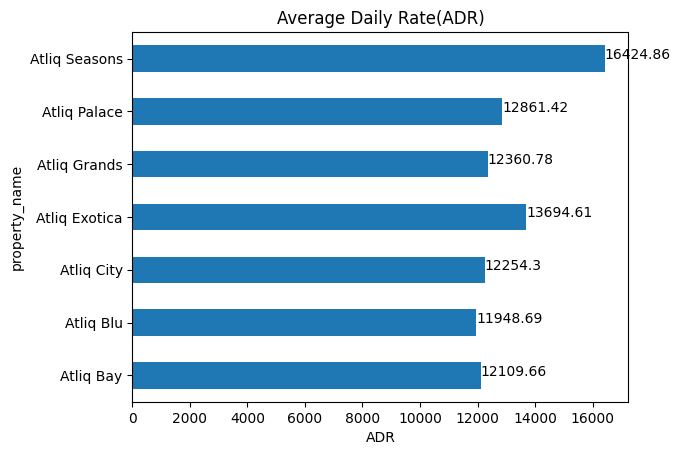

In [417]:
graph = Adr_1.plot(kind='barh',x='property_name',y='ADR',legend=False)
plt.xlabel('ADR')
plt.title("Average Daily Rate(ADR)")
for index,value in enumerate(Adr_1['ADR']):
  graph.text(value,index,str(value))
plt.show()

**DBRN,DSRN,DURN**

In [419]:
min_date = dim_date['date'].min()
max_date = dim_date['date'].max()
total_days = (max_date - min_date).days
total_days

91

**DBRN-Day booking revenue per night**

In [424]:
# DBRN = Adr[['booking_id']]/total_days
# DBRN['booking_id'] = DBRN['booking_id'].round(2)
# DBRN_1 = DBRN.sort_values(by='booking_id',ascending=False)
# DBRN_1

In [425]:
# chart = DBRN_1.plot(kind='barh',y='property_name',legend=False)
# plt.xlabel('DBRN')
# plt.title("DBRN")
# plt.show()

In [426]:
print(Adr.dtypes)

property_name        object
booking_id            int64
revenue_realized    float64
ADR                 float64
dtype: object


In [428]:
Adr['booking_id'] = pd.to_numeric(Adr['booking_id'],errors='coerce')
print(Adr[['property_name','booking_id']].dtypes)

property_name    object
booking_id        int64
dtype: object


In [429]:
DBRN = Adr[['property_name','booking_id']].copy()
DBRN['booking_id'] = DBRN['booking_id']/total_days
DBRN['booking_id'] = DBRN['booking_id'].round(2)
DBRN_1 = DBRN.sort_values(by='booking_id',ascending=False)
DBRN_1

,property_name,booking_id
5,Atliq Palace,107.27
3,Atliq Exotica,107.26
2,Atliq City,106.08
1,Atliq Blu,99.43
0,Atliq Bay,97.60
4,Atliq Grands,77.63
6,Atliq Seasons,17.96


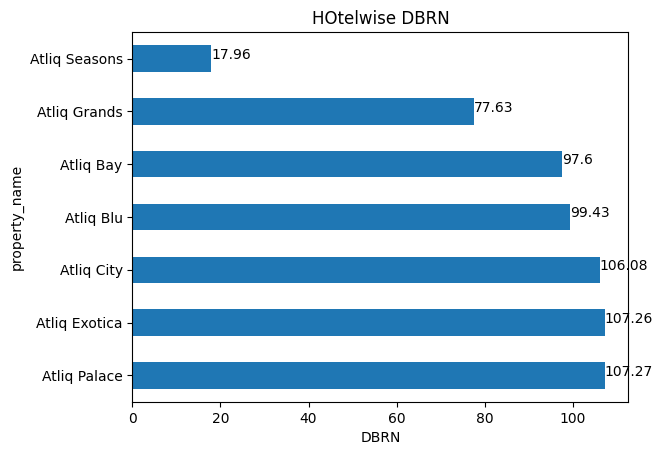

In [432]:
DBRN_1.plot(kind='barh',x='property_name',y='booking_id',legend=False)
plt.xlabel('DBRN')
plt.title("HOtelwise DBRN")
for index,value in enumerate(DBRN_1['booking_id']):
  plt.text(value,index,str(value))
plt.show()

**DSRN - Day sales revenue per night**

In [435]:
hotel_capacity = pd.merge(dim_hotels,fact_agg,on='property_id',how='left').groupby(['property_name']).agg({'capacity':'sum'}).reset_index()
hotel_capacity['DSRN'] = hotel_capacity['capacity']/total_days
hotel_capacity['DSRN'] = hotel_capacity['DSRN'].round(2)
hotel_capacity
hotel_capacity = hotel_capacity.sort_values(by='DSRN')
hotel_capacity = hotel_capacity[['property_name','DSRN']]
hotel_capacity

,property_name,DSRN
6,Atliq Seasons,98.07
4,Atliq Grands,355.87
1,Atliq Blu,385.91
0,Atliq Bay,402.15
2,Atliq City,430.68
5,Atliq Palace,432.70
3,Atliq Exotica,449.89


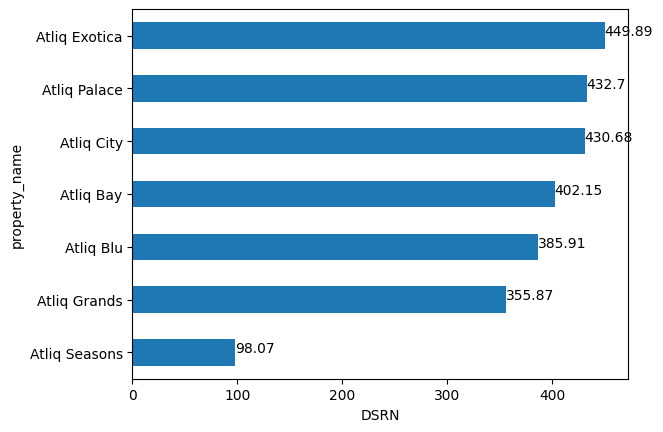

In [437]:
hotel_capacity.plot(kind='barh',x='property_name',y='DSRN',legend=False)
plt.xlabel('DSRN')
for index,value in enumerate(hotel_capacity['DSRN']):
  plt.text(value,index,str(value))
plt.show()

**DURN - day utilization rate per night**

In [440]:
a = revenue_week[revenue_week['booking_status']=='Checked Out']
b = a.groupby(['property_name']).agg({'booking_id':'count'}).reset_index()
b['DURN'] = b['booking_id']/total_days
b['DURN'] = b['DURN'].round(2)
b = b.sort_values(by='DURN')
b = b[['property_name','DURN']]
b

,property_name,DURN
6,Atliq Seasons,12.45
4,Atliq Grands,53.53
0,Atliq Bay,67.97
1,Atliq Blu,69.88
2,Atliq City,74.51
5,Atliq Palace,75.44
3,Atliq Exotica,75.92


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.10/dist-packages/matplotlib/pyplot.py'>

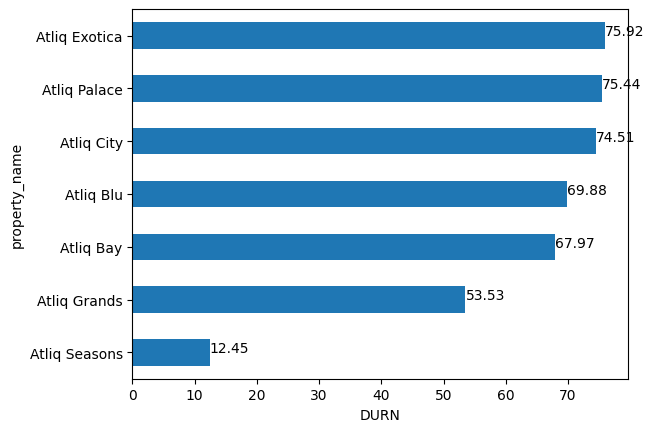

In [441]:
b.plot(kind='barh',x='property_name',y='DURN',legend=False)
plt.xlabel('DURN')
for index,value in enumerate(b['DURN']):
  plt.text(value,index,str(value))
plt